# 11) Natural Language Processing (NLP): from text treatement to Transformers

For text treatment we have the following NNs options:

- *RNNs*: sequential treatment of text, but tend to vanishing or exploding gradient, because weights are multiplied many many times.
- *LSTM*: complex alternative to RNNs that can discard or retain certain informations, avoiding for vanishing or exploding gradient.
- *Transformers*: the fastest and achieving the best results.

>**Transformers-based models** are the most emploied nowadays, based on
>- parallel training;
>- sequential generating;
>- attention mechanism.

## 1) Representing the text

NNs receive tensors and not really strings of carachters. Models for language processing learn the text as follows:

> -> *Text* 
>
> --> *Tokens* (a single carachter, a piece of word, a word) 
>
> ---> *Integer numbers identification* (every token in the vocabulary is associated to a number, for example Unicode) 
>
> ----> *Vector*.

> The NLPs receive the text and "embeddigs" it into a vector. The command 'nn.Embedding(V, C)' identifies each token as a number and represents all the tokens C as embedded into a vocabulary vector V.

### Example:

Consider an English text/sequence on 26 letters == tokens in minuscule font.

There are two more identifiers:
- **BOS**: beginning of the text  (allows to learn when the text starts).
- **EOS**: end of the text        (allows to learn when the text end).

The vocabulary has then 28 items.

For example, in this vocabulary, the name 'emma' is tokenized as 'BOS' 'e' 'm' 'm' 'a' 'EOS'.

Then, we pass the commad 'nn.Embedding(28, tokens)' to embedd the tokens into a vocabulary vector.

## 2) Prediction of the next token

**Goal of NLP**: learning the regularities among the tokens, to be able to predict on an unseen text the next token.

>A *language model* learns the conditional distribution on the vocabularity:
>$$
>P(x_{t+1} \mid x_{0},\dots, x_{1}),
>$$
>i.e. the probability of having token $x_{t+1}$ after tokens $x_{0},\dots,x_{t}$.

Then, once this conditional probability is known, it is possible to predict /generate the next tokens on an unseen sequence of tokens / text.

**Language models are caractherized by:**

> **Parallel Training:** we have a text / a sequence of tokens and we predict SIMULTANEOUSLY / IN A SINGLE STEP / IN PARALLEL the next token for each given token, i.e. 'teacher forcing'.

> **Sequential Generation**: the predicted text on an unseen sequence is outputed sequentially one token at a time.
>
>Rmk) At each time $t$, a *causal mask* covers with $0$ all future tokens, allowing the model to look only at the past generated sequence and denying cheating.

Rmk) The predictive power and strength of Transformers relies on the parallel training.

Rmk) *Transformers are trained on mini-batches, where each train is performed in parallel on the tokens.*

### Example:

**For example**, to generate a name, we start from BOS and choose a token, then we compute the conditionaly probability of having such a token given BOS. We proceed as this until the marker EOS.

## 3) The attention mechanism


The attention mechanism is the gold contribution of transformers.

>During the training phase, transformers rely on **attention**, a mechanism based on the idea that *each token influence its neightbors*.
>
> --> the **attention** is a non-linear layer, that for each token in the text, computes the strenght of its relationship with all the other tokens.
>

**Self attention** because the attention mechanism is addressed to the tokens of the same text.

>FOR EACH TOKEN 3 vectors are computed (that do not depend by the position of the token!!) and then stocked into the matrices:
>
>**Q, query**: what the current token is looking at.
>
>**K, key**: what the current token contains.
>
>**V, value**: what is the information from the match.


>The **attention matrix** is:
>$$
>A = softmax\left( \frac{Q K^{T}}{\sqrt{d}}\right),
>$$
>where $d$ is the total number of tokens
>and the **weighted attention matrix** is then:
>$$
>Z = AV
>$$.

The matrix $A$ returns the scores that rely each token of the text to all the others.

>**Multihead attention**: attention mechanism directed towards different "areas of attention" and relationships between tokens; like for example the grammar, the style, the language of a text.

Rmk) RNNs (recurrent neural networks) pass the informations from the left to the right. But, this mechanism with long sequences is prone to gradient vanishing and therefore to the lost of information. Transformers are a great substitution of RNNs, learning instead through the attention mechanism.

## 4) MicroGPT Transformer : training and generation

### TRAINING PHASE :

>***Architecture***
>
>INPUT 
>
>0) Tokenized text (in entry)
>
>------
>PRE-PROCESSING
>1) *Token embedding*
>
>2) *Positional embedding* (include the positions of tokens; positions not considered by the attention mechanism)
>
>------
>TRANSFORMER BLOCK (repeated many many times)
>
>3) *MultiHead attention*
>
>4) *Layer Normalization* on the token components: $RMSNorm(x)=\dfrac{x}{\sqrt{mean(x^2)+\epsilon}}$
>
>5) *Feed Forward NN == MLP* (typically 1 ReLU layer)
>
>-----
>OUTPUT 
>
>6) Output layer

### GENERATION PHASE :

> - A causal mask covers the future tokens at each step $t$.
> - The transformer computes the probabilities, for the current token, to have as next token all of the other ones.
> - The transformer outputs as next token, the one with highest probability.
> - The next token is given in input to the transformer, as current one.
> - It continues as this until EOS, outputting one token at a time.


For example, it reads 'BOS' and predicts the probability that after 'BOS' there is 'BOS', 'A', 'B', 'C', 'D', .... 'Z', and 'EOS'. It ouputs as next token the one with higher probability, let's say 'C'. Then, 'BOS' 'C' are taked in input to the network, until the process ends with 'EOS'.

## A COMPLETE EXAMPLE

In [39]:
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F

In [40]:
# Vocabulaire
chars = list("abcdefghijklmnopqrstuvwxyz")
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}

BOS, EOS = 26, 27
vocab_size = 28

def encode_name(name):
    return [BOS] + [stoi[ch] for ch in name] + [EOS]


# Facultative : utile pour afficher les tokens sous forme de caractères.
def token_labels(tokens):
    special = {BOS: "BOS", EOS: "EOS"}
    return [special[t] if t in special else itos[t] for t in tokens]



In [41]:
def attention_weights(q, k, causal=True, mask=None):
    # q, k : (..., H, T, d), avec un batch éventuel avant les têtes.
    scores = q @ k.transpose(-2, -1) / math.sqrt(q.size(-1))

    if causal:
        T = q.size(-2)
        allowed = torch.ones(
            T, T, dtype=torch.bool, device=q.device
        ).tril()
        scores = scores.masked_fill(~allowed, float("-inf"))

    if mask is not None:
        # mask : (..., T), True sur les tokens présents ; masque les clés PAD.
        scores = scores.masked_fill(
            ~mask[..., None, None, :],
            float("-inf"),
        )

    return scores.softmax(dim=-1)

In [42]:
def rms_norm(x):
    return x * torch.rsqrt(
        x.square().mean(dim=-1, keepdim=True) + 1e-5
    )

In [43]:
def split_heads(x, heads):
    # (T, C) -> (H, T, d), ou (B, T, C) -> (B, H, T, d).
    *prefix, T, C = x.shape
    return (
        x.reshape(*prefix, T, heads, C // heads)
        .transpose(-3, -2)
    )

def merge_heads(x):
    # Opération inverse ; conserve le batch éventuel.
    *prefix, H, T, d = x.shape
    return (
        x.transpose(-3, -2)
        .contiguous()
        .view(*prefix, T, H * d)
    )

In [44]:
class SelfAttention(nn.Module):
    def __init__(self, d_model, heads, causal=True):
        super().__init__()
        assert d_model % heads == 0

        self.heads = heads
        self.causal = causal
        self.qkv = nn.Linear(d_model, 3 * d_model, bias=False)
        self.proj = nn.Linear(d_model, d_model, bias=False)

    def forward(self, x, mask=None):
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        q, k, v = [
            split_heads(z, self.heads)
            for z in (q, k, v)
        ]

        weights = attention_weights(
            q,
            k,
            causal=self.causal,
            mask=mask,
        )
        self.last_weights = weights.detach()  # Pour l'affichage seulement.

        return self.proj(merge_heads(weights @ v))

In [45]:
class TransformerBlock(nn.Module):
    def __init__(self, d_model, heads, causal=True):
        super().__init__()
        self.attn = SelfAttention(
            d_model,
            heads,
            causal=causal,
        )
        self.mlp = nn.Sequential(
            nn.Linear(d_model, 4 * d_model, bias=False),
            nn.ReLU(),
            nn.Linear(4 * d_model, d_model, bias=False),
        )

    def forward(self, x, mask=None):
        x = x + self.attn(rms_norm(x), mask=mask)
        x = x + self.mlp(rms_norm(x))
        return x

In [46]:
class MicroGPT(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, n_embd)
        self.pos_emb = nn.Embedding(block_size, n_embd)
        self.blocks = nn.ModuleList([
            TransformerBlock(n_embd, n_head, causal=True)
            for _ in range(n_layer)
        ])
        self.lm_head = nn.Linear(n_embd, vocab_size, bias=False)

    def forward(self, tokens):
        T = tokens.size(-1)
        assert 0 < T <= block_size

        positions = torch.arange(T, device=tokens.device)
        x = self.token_emb(tokens) + self.pos_emb(positions)

        for block in self.blocks:
            x = block(x)

        return self.lm_head(rms_norm(x))
        # (T, V) ou (B, T, V), sans softmax.


In [47]:
# Initialisation et vérification du modèle
n_embd, n_head , n_layer = 16, 4, 1
block_size = 16 
steps, learning_rate = 1000, 0.003
docs = [
    "isabella", "emma", "chiara", "sara", "alice", "amelia", "olivia",
    "sophia", "mia", "charlotte", "ava", "ella", "grace", "lily",
    "chloe", "zoe", "lucy", "layla", "nora", "maya", "aria",
    "elena", "clara", "julia", "laura", "anna", "bella", "ruby",
    "rose", "violet", "hazel", "stella", "leah", "naomi", "eliza",
    "madeline", "evelyn", "willow", "freya", "thea", "mila",
    "luca", "leo", "noah", "liam", "oliver", "elijah", "james",
    "henry", "theo", "jack", "charlie", "julian", "isaac",
    "felix", "oscar", "arthur", "milo", "ezra", "owen", "mason",
    "ethan", "gabriel", "daniel", "samuel", "sebastian", "david",
    "alexander", "benjamin", "thomas", "max", "adam", "nathan",
    "lucas", "mateo", "andrew", "joseph", "caleb", "ryan",
    "ian", "victor", "marco", "antonio", "diego", "rafael",
]

# Conserver EOS sans dépasser le contexte ; pas de troncature silencieuse.
eligible = sorted(
    {
        name
        for name in docs
        if len(name) <= block_size - 1
        and set(name) <= set(chars)
    }
)

if len(eligible) < 2:
    raise ValueError(
        f"Need at least 2 eligible names to split into train and validation; "
        f"found {len(eligible)}. Check docs and block_size."
    )

random.Random(42).shuffle(eligible)

n_valid = min(128, max(1, len(eligible) // 10))
train_names = eligible[:-n_valid]
valid_examples = eligible[-n_valid:]

print(
    len(train_names),
    "train ;",
    len(valid_examples),
    "validation",
)


77 train ; 8 validation


In [48]:
model = MicroGPT()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate,
    betas=(0.9, 0.95),
)

print(
    "Paramètres :",
    sum(p.numel() for p in model.parameters()),
)

Paramètres : 4224


In [49]:
def name_tensors(name):
    tokens = encode_name(name)
    return (
        torch.tensor(tokens[:-1]),
        torch.tensor(tokens[1:]),
    )


def micro_step(name):
    model.train()
    x, y = name_tensors(name)

    optimizer.zero_grad(set_to_none=True)
    loss = F.cross_entropy(model(x), y)
    loss.backward()
    optimizer.step()

    return loss.item()

In [50]:
@torch.no_grad()
def micro_validation():
    was_training = model.training
    model.eval()

    losses = []
    for name in valid_examples:
        x, y = name_tensors(name)
        losses.append(F.cross_entropy(model(x), y).item())

    model.train(was_training)
    return float(np.mean(losses))


print(
    "Validation avant entraînement :",
    round(micro_validation(), 3),
)

Validation avant entraînement : 3.731


Pas  200 | validation : 2.751
Pas  400 | validation : 2.609
Pas  600 | validation : 2.705
Pas  800 | validation : 2.613
Pas 1000 | validation : 2.744


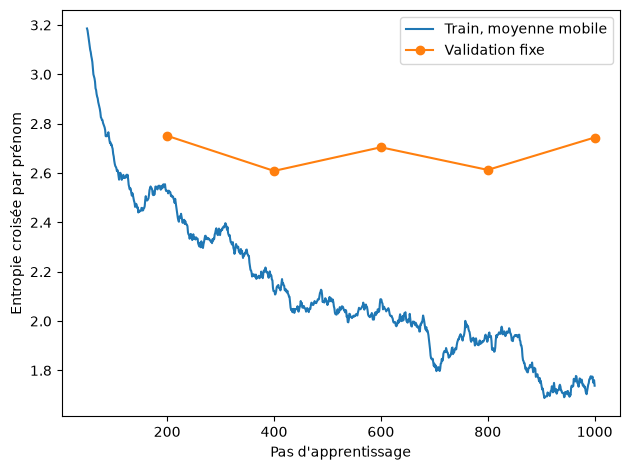

In [51]:
# Entraînement et validation
losses, validation_curve = [], []
sampling_rng = random.Random(42)

for step in range(steps):
    losses.append(micro_step(sampling_rng.choice(train_names)))

    if (step + 1) % 200 == 0:
        value = micro_validation()
        validation_curve.append((step + 1, value))
        print(f"Pas {step + 1:4d} | validation : {value:.3f}")

# Courbes d'entraînement et de validation
window = min(50, len(losses))

smooth = np.convolve(
    losses,
    np.ones(window) / window,
    mode="valid",
)

plt.plot(
    np.arange(window, len(losses) + 1),
    smooth,
    label="Train, moyenne mobile",
)

positions, values = np.asarray(validation_curve).T
plt.plot(positions, values, "o-", label="Validation fixe")

plt.xlabel("Pas d'apprentissage")
plt.ylabel("Entropie croisée par prénom")
plt.legend()
plt.tight_layout()
plt.show()

In [52]:
# Génération
@torch.no_grad()
def generate(temperature=0.8):
    if temperature <= 0:
        raise ValueError("La température doit être strictement positive.")

    was_training = model.training
    model.eval()

    tokens = [BOS]
    stopped = False

    for _ in range(block_size):
        logits = model(
            torch.tensor(tokens, device=device)
        )[-1].clone()

        logits[BOS] = float("-inf")  # BOS sert seulement à démarrer.
        probs = (logits / temperature).softmax(dim=-1)
        next_token = torch.multinomial(probs, 1).item()

        if next_token == EOS:
            stopped = True
            break

        tokens.append(next_token)

    model.train(was_training)

    name = "".join(itos[t] for t in tokens[1:])
    return name if stopped else name + " [limite]"


## 5) Subtokens

> Actual transformers focus on *subtokens*==pieces of words, instaed than *tokens / words*.

>*The most common terms are considered as single subtokens and the other terms are splitted into more frequent subtokens.* As this, it takes into account:
>
>- rare words;
>- person names;
>- flexions;
>- neologisms.

This permits to eventually considering carachters as separate items, than to merge adjacent tokens depending on the probability, and so on, until real words are generated.

*Example*: starts from 'l' 'o' 'w', then merges 'lo' 'w', and finally 'low'.

## 6) Padding

> - To work with texts of different sizes, fix a maximum lenght.
> - For each text, add a padding after the end, i.e. EOS.

In other words, apply a casual mask to the text, with 1 in correspondence of subtokens and 0s after 'EOS'.

Rmk) This padding is useful in the MultiHead Attention layer.

> Rmk) THERE EXISTS TWO CAUSAL MASKS:
>1) during the generation phase, to hide the future;
>2) for the attention mechanism, to cover as 0 the empty subtokens.

## 7) Encoder / Decoder structure

>There exist 3 kind of transformers:
>
>- Only encoder: processes the whole document using bidirectional attention (ex. BERT).
>- Encoder / Decoder: whole document and labels (ex. initial transformers / the encoder for training and the decoder for generation).
>- Only decoder: processes a prefix and next tokens are generated using causal attention (ex. GPT).

Rmk) Currently, transformers are *decoder only*. In this file also we treated MicroGPT, which is a decoder only.